In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sol_to_earth = 332946.078

In [2]:
cham_cont_as = np.loadtxt("/Users/honeyeah/Codes/data/cham_cont/cham_cont_47/cont_semis.txt")
cham_cont_ms = np.loadtxt("/Users/honeyeah/Codes/data/cham_cont/cham_cont_47/cont_masses.txt")

In [3]:
cham_cont_df = pd.DataFrame(columns=['m', 'a'])
cham_cont_df['m'] = cham_cont_ms
cham_cont_df['a'] = cham_cont_as

In [4]:
inner_disk_mass = 0
outer_disk_mass = 0
inners_cont = []
outers_cont = []
inners_bench = []
outers_bench = []

bounds = [0.5, 0.6, 0.7, 0.8]
for bound in bounds:
    for i in range(len(cham_cont_df)):
        if cham_cont_df['a'].iloc[i] < bound:
            inner_disk_mass += cham_cont_df['m'].iloc[i]
        else:
            outer_disk_mass += cham_cont_df['m'].iloc[i]
    inners_cont.append(inner_disk_mass)
    outers_cont.append(outer_disk_mass)
    print(f"mass_inner for b = {bound} is {inner_disk_mass}")
    print(f"mass_outer for b = {bound} is {outer_disk_mass}")

inners_cont = np.array(inners_cont)
outers_cont = np.array(outers_cont)

mass_inner for b = 0.5 is 3.64842144e-07
mass_outer for b = 0.5 is 7.2513924799999945e-06
mass_inner for b = 0.6 is 9.00524738e-07
mass_outer for b = 0.6 is 1.433194451e-05
mass_inner for b = 0.7 is 1.7347400219999998e-06
mass_outer for b = 0.7 is 2.1113963850000012e-05
mass_inner for b = 0.8 is 3.527816046e-06
mass_outer for b = 0.8 is 2.6937122450000023e-05


In [5]:
cham_bench_embs = np.loadtxt("/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_3/cham_bimodal_emb_samples_sep3.txt")
cham_bench_pls = np.loadtxt("/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_3/cham_bimodal_pl_samples_sep3.txt")
emb_masses = np.ones(14) * 2.8e-7
pl_masses = np.ones(140) * 2.8e-8

cham_semis = np.concatenate([cham_bench_embs, cham_bench_pls])
cham_masses = np.concatenate([emb_masses, pl_masses])

cham_bench_df = pd.DataFrame(columns=['m', 'a'])
cham_bench_df['a'] = cham_semis
cham_bench_df['m'] = cham_masses

In [6]:
inner_disk_mass = 0
outer_disk_mass = 0

bounds = [0.5, 0.6, 0.7, 0.8]
for bound in bounds:
    for i in range(len(cham_bench_df)):
        if cham_bench_df['a'].iloc[i] < bound:
            inner_disk_mass += cham_bench_df['m'].iloc[i]
        else:
            outer_disk_mass += cham_bench_df['m'].iloc[i]

    inners_bench.append(inner_disk_mass)
    outers_bench.append(outer_disk_mass)

inners_bench = np.array(inners_bench)
outers_bench = np.array(outers_bench)

In [13]:
inners_bench[0]

np.float64(1.12e-07)

In [14]:
outers_bench[0]

np.float64(7.728000000000055e-06)

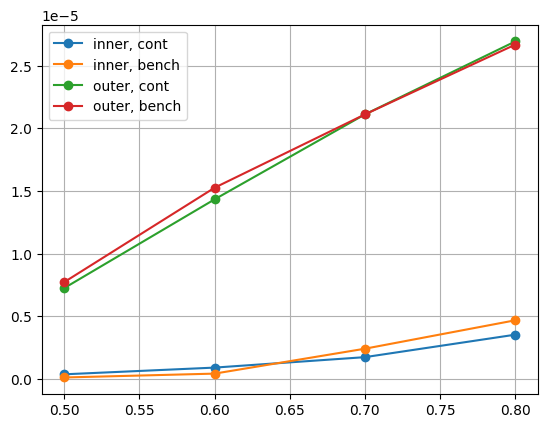

In [7]:
plt.plot(bounds, inners_cont, label = 'inner, cont', marker='o')
plt.plot(bounds, inners_bench, label = 'inner, bench',  marker='o')

plt.plot(bounds, outers_cont, label = 'outer, cont', marker='o')
plt.plot(bounds, outers_bench, label = 'outer, bench', marker='o')

plt.grid('True')
plt.legend()

In [8]:
def cmf_inner(x, m_inner, m_outer, cmf_tot = 0.33):
    cmf_i = (cmf_tot*m_inner + (x * cmf_tot * m_outer))/m_inner
    return cmf_i

In [9]:
cmf_inners_cont = []
cmf_outers_cont = []
cmf_inners_bench = []
cmf_outers_bench = []

percs = [0.05, 0.10, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4]


for perc in percs:
    cmf_inners_bench.append(cmf_inner(x=perc, m_inner=inners_bench[1], m_outer=outers_bench[1]))
    cmf_inners_cont.append(cmf_inner(x=perc, m_inner=inners_cont[1], m_outer=outers_cont[1]))

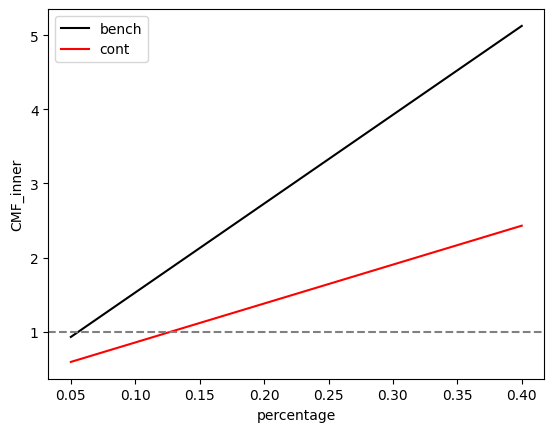

In [10]:
plt.plot(percs, cmf_inners_bench, color = 'black', label = 'bench')
plt.plot(percs, cmf_inners_cont, color = 'red', label = 'cont')

plt.axhline(1, linestyle='--', color='gray')

plt.xlabel('percentage')
plt.ylabel('CMF_inner')
plt.legend()

Text(0, 0.5, 'M_inner,cont - M_inner,bench')

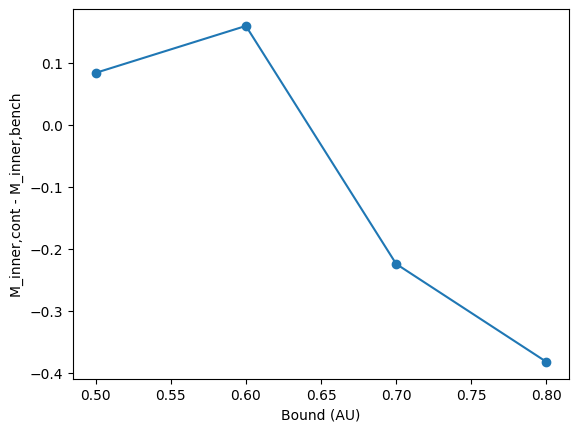

In [11]:
plt.plot(bounds, (inners_cont - inners_bench) * sol_to_earth, marker='o')
plt.xlabel('Bound (AU)')
plt.ylabel("M_inner,cont - M_inner,bench")